# 2025 — Tiny Recursive Models: Depth Through Recursion

**Papers:** Alexia Jolicoeur-Martineau, *"Less is More: Recursive Reasoning with Tiny Networks"* (TRM, October 2025); predecessor: Wang et al., *"Hierarchical Reasoning Model"* (HRM, 2025). Related ideas: Universal Transformers (2018), deep equilibrium models (2019).

A 2025 counter-trend to scale: on hard puzzles (Sudoku-Extreme, mazes, ARC-AGI) a **7M-parameter** network that **reuses itself recursively** beat far larger LLMs. TRM keeps two states:
- $y$: the current **answer** (embedded)
- $z$: a latent **reasoning** state

and one tiny network $f$ that repeatedly refines them:

```
for n steps:  z = f(x + y + z)     # think: update the reasoning given question, answer, latent
y = f(y + z)                        # act: update the answer from the reasoning
```

Training uses **deep supervision**: run several "supervision steps", each computing a loss on $y$ and then **detaching** $(y, z)$ before the next. The model learns to improve *any* current answer, and gradients only flow through the last recursion (cheap memory).

**Our task:** 4×4 Sudoku (digits 1–4, each row, column and 2×2 box must contain all four) with 6–10 empty cells. We train on puzzles from 240 solution grids and test on puzzles from **48 unseen grids**.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import itertools

PyTorch 2.15.0 | device: mps


In [2]:
def valid(g):
    rows = all(len(set(r)) == 4 for r in g)
    cols = all(len({g[r][c] for r in range(4)}) == 4 for c in range(4))
    boxes = all(len({g[r][c] for r in (br, br + 1) for c in (bc, bc + 1)}) == 4 for br in (0, 2) for bc in (0, 2))
    return rows and cols and boxes
perms = list(itertools.permutations([1, 2, 3, 4]))
grids = [g for g in itertools.product(perms, repeat=4) if valid(g)]
print("number of valid 4x4 sudoku grids:", len(grids))
rng = np.random.default_rng(0)
grids = torch.tensor(np.array(grids)[rng.permutation(len(grids))]).view(-1, 16)
train_grids, test_grids = grids[:240], grids[240:]

def make_puzzles(sol, B=128, n_blank_range=(6, 11)):
    sol = sol[torch.randint(0, len(sol), (B,))]
    blank = torch.rand(B, 16).argsort(1) < torch.randint(*n_blank_range, (B, 1))   # 6-10 random empty cells
    x = sol.clone(); x[blank] = 0                                                   # 0 = empty cell
    return x.to(device), (sol - 1).to(device)                                       # targets 0..3

def is_solved(puzzle, pred):
    """A puzzle with many blanks can have several solutions, so we score *validity*:
    the answer must keep every clue and be a correct sudoku."""
    g = (pred + 1).view(-1, 4, 4); full = torch.arange(1, 5, device=g.device)
    keeps_clues = ((puzzle == 0) | (puzzle == pred + 1)).all(1)
    rows = (g.sort(2).values == full).all(2).all(1)
    cols = (g.transpose(1, 2).sort(2).values == full).all(2).all(1)
    boxes = (g.view(-1, 2, 2, 2, 2).permute(0, 1, 3, 2, 4).reshape(-1, 4, 4).sort(2).values == full).all(2).all(1)
    return keeps_clues & rows & cols & boxes

number of valid 4x4 sudoku grids: 288


In [3]:
class TinyNet(nn.Module):
    """The single small network f: 2 Transformer layers over the 16 cells."""
    def __init__(self, d=64):
        super().__init__()
        layer = nn.TransformerEncoderLayer(d, 4, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.body = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False); self.norm = nn.LayerNorm(d)
    def forward(self, h): return self.norm(self.body(h))

class TRM(nn.Module):
    def __init__(self, d=64, n=3, T=2):
        super().__init__()
        self.n, self.T = n, T
        self.x_emb, self.pos = nn.Embedding(5, d), nn.Parameter(torch.randn(16, d) * 0.02)
        self.y0, self.z0 = nn.Parameter(torch.randn(d) * 0.02), nn.Parameter(torch.randn(d) * 0.02)
        self.f = TinyNet(d); self.out = nn.Linear(d, 4)

    def init_state(self, B): return self.y0.expand(B, 16, -1), self.z0.expand(B, 16, -1)

    def latent_recursion(self, x, y, z):
        for _ in range(self.n): z = self.f(x + y + z)                   # refine reasoning n times
        y = self.f(y + z)                                               # then refine the answer
        return y, z

    def deep_recursion(self, x, y, z):
        with torch.no_grad():                                           # T-1 recursions without gradients
            for _ in range(self.T - 1): y, z = self.latent_recursion(x, y, z)
        y, z = self.latent_recursion(x, y, z)                           # the last one with gradients
        return (y.detach(), z.detach()), self.out(y)

    def embed(self, puzzle): return self.x_emb(puzzle) + self.pos

In [4]:
def train(model, iters=800, n_sup=4):
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    for it in range(iters):
        puzzle, target = make_puzzles(train_grids)
        x = model.embed(puzzle); y, z = model.init_state(len(x))
        for s in range(n_sup):                                          # deep supervision
            (y, z), logits = model.deep_recursion(x, y, z)
            loss = F.cross_entropy(logits.reshape(-1, 4), target.reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
            x = model.embed(puzzle)                                     # re-embed after the parameter update
        if it % 200 == 0: print(f"iter {it:3d}  loss at last supervision step {loss.item():.4f}")

@torch.no_grad()
def evaluate(model, grids, n_sup):
    puzzle, _ = make_puzzles(grids, B=1000)
    x = model.embed(puzzle); y, z = model.init_state(len(x)); solved = []
    for s in range(n_sup):
        (y, z), logits = model.deep_recursion(x, y, z)
        solved.append(is_solved(puzzle, logits.argmax(-1)).float().mean().item())
    return solved

seed_everything(0)
trm = TRM().to(device)
print(f"parameters: {sum(p.numel() for p in trm.parameters()) / 1e3:.0f}K")
t0 = time.time(); train(trm); print(f"trained in {time.time() - t0:.0f}s")

parameters: 69K


iter   0  loss at last supervision step 1.1897


iter 200  loss at last supervision step 0.6500


iter 400  loss at last supervision step 0.6191


iter 600  loss at last supervision step 0.1398


trained in 203s


## More thinking at test time → better answers
Each supervision step is another round of recursion. Measured on puzzles from **unseen** solution grids. With deep supervision the model is trained to give a good answer after *every* step, so most of the accuracy is already there after the first step (which itself contains T×(n+1) = 8 network applications). Accuracy keeps rising up to about the number of steps used in training, then plateaus or drifts slightly. The real TRM adds a learned halting head (ACT) that decides when to stop.

after  1 supervision steps: valid solutions 0.802
after  2 supervision steps: valid solutions 0.799
after  3 supervision steps: valid solutions 0.796
after  4 supervision steps: valid solutions 0.791
after  5 supervision steps: valid solutions 0.782
after  6 supervision steps: valid solutions 0.772
after  7 supervision steps: valid solutions 0.770
after  8 supervision steps: valid solutions 0.763
after  9 supervision steps: valid solutions 0.760
after 10 supervision steps: valid solutions 0.758


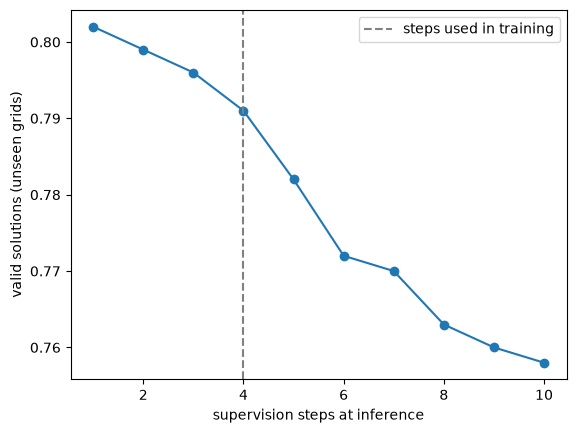

In [5]:
curve = evaluate(trm, test_grids, n_sup=10)
for s, acc in enumerate(curve, 1): print(f"after {s:2d} supervision steps: valid solutions {acc:.3f}")
plt.plot(range(1, 11), curve, marker="o"); plt.axvline(4, ls="--", c="gray", label="steps used in training")
plt.xlabel("supervision steps at inference"); plt.ylabel("valid solutions (unseen grids)"); plt.legend(); plt.show()

## Baseline: the same tiny network applied once

In [6]:
class OneShot(nn.Module):
    def __init__(self, d=64):
        super().__init__(); self.x_emb, self.pos = nn.Embedding(5, d), nn.Parameter(torch.randn(16, d) * 0.02); self.f = TinyNet(d); self.out = nn.Linear(d, 4)
    def forward(self, p): return self.out(self.f(self.x_emb(p) + self.pos))
seed_everything(0)
base = OneShot().to(device); opt = torch.optim.AdamW(base.parameters(), lr=1e-3, weight_decay=0.01)
for it in range(800 * 4):                                                # same number of optimizer steps as TRM
    p, t = make_puzzles(train_grids)
    loss = F.cross_entropy(base(p).reshape(-1, 4), t.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    p, _ = make_puzzles(test_grids, B=1000); acc = is_solved(p, base(p).argmax(-1)).float().mean().item()
print(f"same tiny network applied once: {acc:.3f} valid solutions | TRM after 4 steps: {curve[3]:.3f}")

same tiny network applied once: 0.727 valid solutions | TRM after 4 steps: 0.791


## Takeaways
- Same parameters, more *computation*: recursion turns a small network into a deep one, and deep supervision trains it to keep improving its own answer.
- On the real benchmarks (9×9 Sudoku-Extreme, mazes, ARC-AGI) the paper reports that a 7M-parameter TRM beats much larger LLMs. Whether recursion of this kind scales to general language tasks is an open 2026 research question.